In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
!pip install ROOT

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 247.9/247.9 MB 15.6 MB/s  0:00:15


In [3]:
import random

In [25]:
rs = []
for i in range(10000):
  rs.append(random.gauss(0, 1))

In [23]:
rs = np.random.normal(0, 1, 10000)

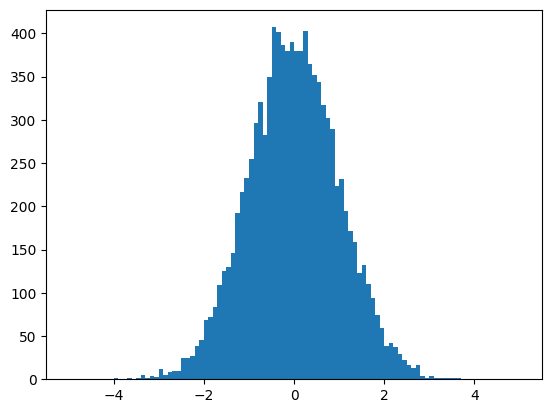

In [26]:
plt.hist(rs, bins=100, range=(-5, 5));

In [28]:
import ROOT

/usr/local/lib/python3.13/dist-packages/ROOT/__init__.py:222: UserWarning: 
This distribution of ROOT is in alpha stage. Feedback is welcome and appreciated. Feel free to reach out to the user forum for questions and general feedback at https://root-forum.cern.ch or to submit an issue at https://github.com/root-project/root/issues. Do not rely on this distribution for production purposes.

  warnings.warn(


In [29]:
rnd = ROOT.TRandom()

In [32]:
rs = []
for i in range(10000):
  rs.append(rnd.Uniform(-1, 1))

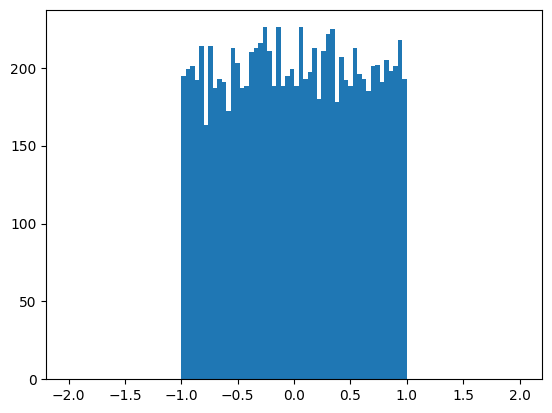

In [34]:

plt.hist(rs, bins=100, range=(-2, 2));

Warning in <TROOT::Append>: Replacing existing TH1: h (Potential memory leak).
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c


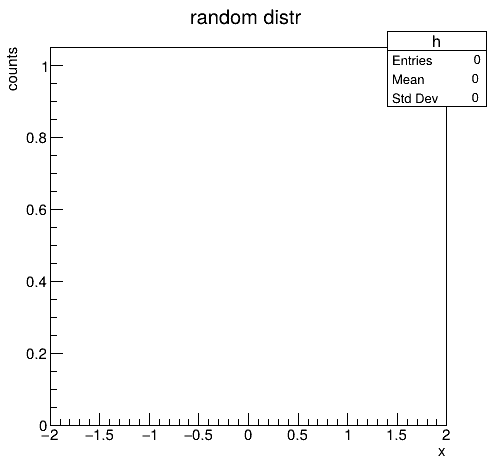

In [39]:
h = ROOT.TH1D("h", "random distr;x;counts", 100, -2, 2)
c = ROOT.TCanvas("c", "c", 500, 500)
h.Draw()
c.Draw()

In [40]:
for i in range(10000):
  r = rnd.Uniform(-1, 1)
  h.Fill(r)

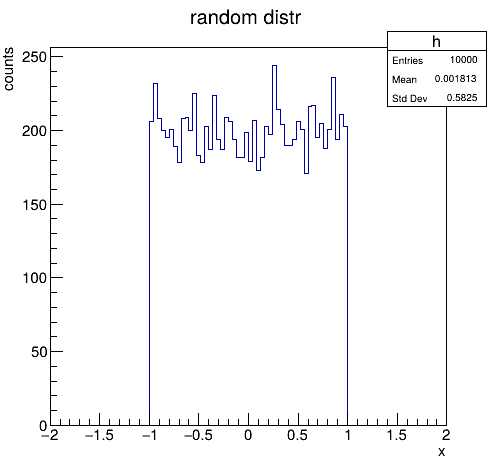

In [41]:
h.Draw()
c.Draw()

In [44]:
import ctypes

In [72]:
h1eta = ROOT.TH1D("h1eta", "gamma1_eta;Pseudorapidity #eta;Entries", 100, -5, 5)
h1theta = ROOT.TH1D("h1theta", "gamma1_eta;Angle #theta;Entries", 100, 0, ROOT.TMath.Pi())
h1phi = ROOT.TH1D("h1phi", "gamma1 phi;Azimuthal angle #phi;Entries", 100, -ROOT.TMath.Pi(), ROOT.TMath.Pi())
h1pt  = ROOT.TH1D("h1pt", "gamma1 pt;Transverse momentum [GeV/c];Entries", 100, 0, 100)

m = 125.0
higgsP4 = ROOT.TLorentzVector()
higgsP4.SetXYZM(0,0,1000,m)

gamma1E = m/2
gamma2E = m/2
gamma1P4 = ROOT.TLorentzVector()
#help(rnd.Sphere)
nExp = 10000
px1, py1, pz1 = ctypes.c_double(0.), ctypes.c_double(0.), ctypes.c_double(0.)

for i in range(nExp):
  rnd.Sphere(px1, py1, pz1, gamma1E)
  #gamma1P4 = ROOT.TLorentzVector(px1, py1, pz1, gamma1E)
  gamma1P4.SetPxPyPzE(px1, py1, pz1, gamma1E)
  gamma2P4 = -gamma1P4

  gamma1P4.Boost(higgsP4.BoostVector())
  gamma2P4.Boost(higgsP4.BoostVector())

  h1eta.Fill(gamma1P4.Eta())
  h1theta.Fill(gamma1P4.Theta())
  h1phi.Fill(gamma1P4.Phi())
  h1pt.Fill(gamma1P4.Pt())

Warning in <TROOT::Append>: Replacing existing TH1: h1eta (Potential memory leak).
Warning in <TROOT::Append>: Replacing existing TH1: h1theta (Potential memory leak).
Warning in <TROOT::Append>: Replacing existing TH1: h1phi (Potential memory leak).
Warning in <TROOT::Append>: Replacing existing TH1: h1pt (Potential memory leak).


Warning in <TCanvas::Constructor>: Deleting canvas with same name: c2


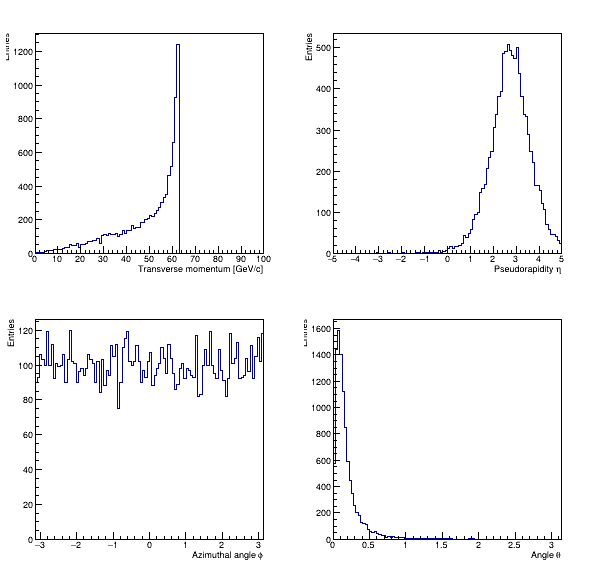

In [73]:
ROOT.gStyle.SetOptStat(0)
ROOT.gStyle.SetOptTitle(0)
c2 = ROOT.TCanvas("c2", "c2", 600, 600)
c2.Divide(2,2)
h1phi.SetMinimum(0)
#
c2.cd(1)
h1pt.Draw()
c2.cd(2)
h1eta.Draw()
c2.cd(3)
h1phi.Draw()
c2.cd(4)
h1theta.Draw()
c2.Draw()

In [74]:
gen = ROOT.TGenPhaseSpace()

In [97]:
higgsP4.SetPtEtaPhiM(0,0,0,125)

h1eta.Reset()
h1theta.Reset()
h1phi.Reset()
h1pt.Reset()
h1p = h1pt.Clone("h1p")
h1p.SetTitle("momentum;p GeV;Entries")

masses = np.array([0., 0., 0.])
gen.SetDecay(higgsP4, len(masses), masses)
for i in range(1000):
  weight = gen.Generate()
  p1 = gen.GetDecay(0)
  #p2 = gen.GetDecay(1)
  #print(p1.Px(), p2.Px())

  h1eta.Fill(p1.Eta(), weight)
  h1theta.Fill(p1.Theta(), weight)
  h1phi.Fill(p1.Phi(), weight)
  h1pt.Fill(p1.Pt(), weight)
  h1p.Fill(p1.P(), weight)

Warning in <TCanvas::Constructor>: Deleting canvas with same name: c2


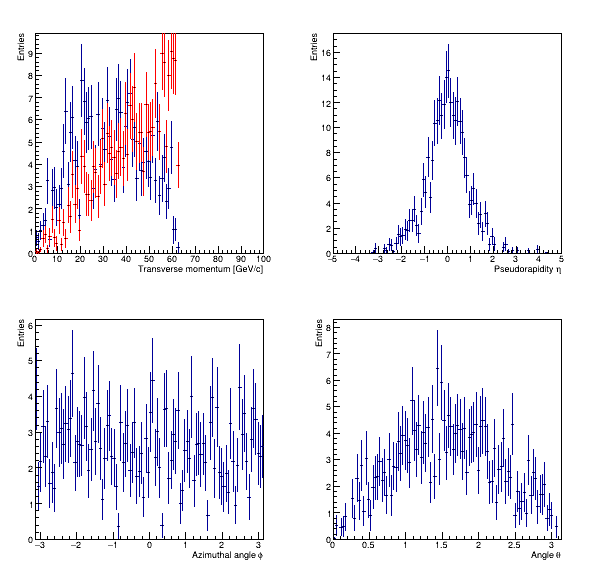

In [98]:
c2 = ROOT.TCanvas("c2", "c2", 600, 600)
c2.Divide(2,2)
h1phi.SetMinimum(0)
#
h1p.SetLineColor(ROOT.kRed)
c2.cd(1)
h1pt.Draw()
h1p.Draw("same")
c2.cd(2)
h1eta.Draw()
c2.cd(3)
h1phi.Draw()
c2.cd(4)
h1theta.Draw()
c2.Draw()